# 02 · Feature engineering and selection

**CRISP-DM phase: Data preparation.**

The numbers come from `python -m src.features.selection`, which works on the training split only. Run that first if the CSV files in `reports/` are missing.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from src.config.settings import PROJECT_ROOT, get_settings
from src.data.loader import load_data
from src.features.engineering import add_behavioural_features

settings = get_settings()
REPORTS = PROJECT_ROOT / "reports"
with_pv = pd.read_csv(REPORTS / "feature_importance_with_page_values.csv", index_col=0)
without_pv = pd.read_csv(REPORTS / "feature_importance_without_page_values.csv", index_col=0)
with_pv.head()

,gain_share,permutation_mean,permutation_std,drop_candidate
PageValues,0.65192,0.59380,0.01319,False
ProductRelated,0.05288,0.03488,0.01115,False
total_pages,0.03038,0.01801,0.00621,False
BounceRates,0.02695,0.01565,0.00225,False
ExitRates,0.03707,0.01467,0.00303,False


## 1. The engineered features

| Feature | Meaning | Why try it |
|---|---|---|
| `total_pages` | All pages viewed | Overall engagement |
| `total_duration` | Total time in the session | Overall engagement |
| `avg_time_per_page` | Time per page | Browsing or reading closely |
| `avg_time_per_product_page` | Time per product page | Interest in products |
| `product_page_share` | Share of pages about products | Shopping or just looking around |
| `product_time_share` | Share of time on products | Same, measured in time |

In [2]:
df = add_behavioural_features(load_data())
new_columns = settings.engineered_log_scaled_features + settings.engineered_scaled_features
df.groupby(settings.target)[new_columns].median().T.rename(columns={0: "non-buyer median", 1: "buyer median"}).round(3)

Converted,non-buyer median,buyer median
total_pages,18.000,35.000
total_duration,505.264,1008.910
avg_time_per_page,29.015,29.333
avg_time_per_product_page,29.875,29.638
product_page_share,0.882,0.917
product_time_share,0.926,0.948


**Takeaway:** buyers look different on the engineered features too, but that does not guarantee they add anything the model cannot already get from the raw columns. The next sections test that.

## 2. Importance with PageValues

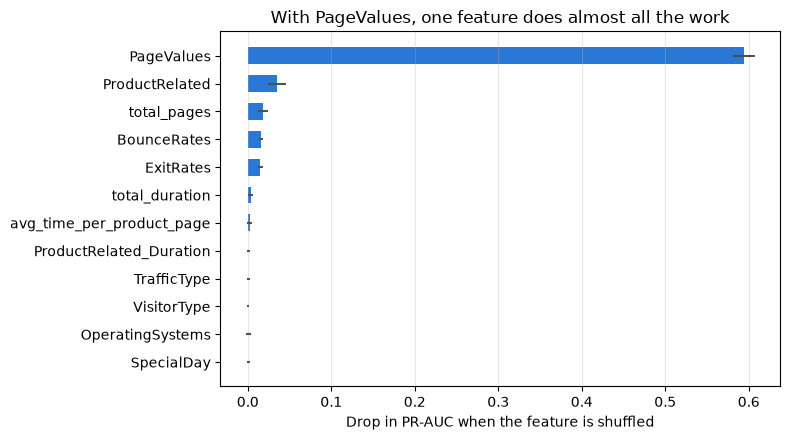

In [3]:
def plot_permutation(ranking, title, top=12):
    data = ranking.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.barh(data.index, data["permutation_mean"], xerr=data["permutation_std"], color="#2a78d6", height=0.6, ecolor="#52514e")
    ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_permutation(with_pv, "With PageValues, one feature does almost all the work")

**Takeaway:** shuffling PageValues costs about 0.59 of PR-AUC, and the next feature costs about 0.03. With a feature this strong, the others can look useless even when they hold real signal.

## 3. Importance without PageValues

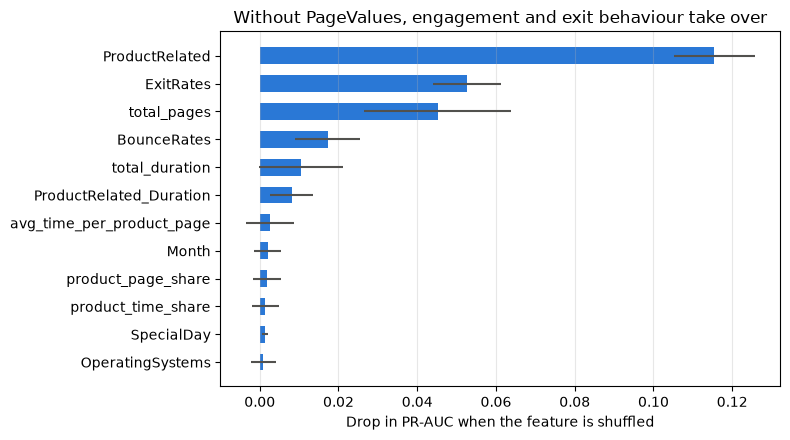

In [4]:
plot_permutation(without_pv, "Without PageValues, engagement and exit behaviour take over")

**Takeaway:** ProductRelated, ExitRates and total_pages become the leading signals. Month also moves out of the weak group, which is why we ranked twice before dropping anything.

## 4. The decision

A column is weak when its gain share is under 1% **and** its permutation importance is no bigger than the noise between folds. We only drop columns that are weak in both rankings.

In [5]:
weak = with_pv.index[with_pv["drop_candidate"]].intersection(without_pv.index[without_pv["drop_candidate"]])
print("Weak in both:", sorted(weak))
print("Dropped in config:", sorted(settings.dropped_features))

Weak in both: ['Administrative', 'Informational', 'VisitorType', 'Weekend']
Dropped in config: ['Administrative', 'Informational', 'VisitorType', 'Weekend']


Cross-validated PR-AUC from the selection script (training split, no imbalance handling):

| Feature set | LightGBM | Logistic Regression |
|---|---|---|
| Raw columns only | 0.8334 ± 0.0046 | 0.8299 ± 0.0157 |
| Raw + engineered | 0.8352 ± 0.0088 | 0.8304 ± 0.0156 |
| Without weak features | 0.8352 ± 0.0036 | 0.8310 ± 0.0158 |
| No PageValues, raw only | 0.4958 ± 0.0248 | 0.5228 ± 0.0149 |
| No PageValues, raw + engineered | 0.4962 ± 0.0284 | 0.5221 ± 0.0160 |
| No PageValues, without weak features | 0.4997 ± 0.0273 | 0.5245 ± 0.0151 |

**What this shows:**

- Dropping the four weak columns does not lower PR-AUC, so the simpler model is the better choice.
- The engineered features give no measurable gain; every difference is inside the fold noise. We keep them because they pass the selection rule and are easy to explain, not because they raised the score.
- Removing PageValues takes PR-AUC from about 0.83 to about 0.50. Most of the model's strength comes from this one column, which may not be known when a session needs scoring.

**Limitation:** correlated columns such as ProductRelated and total_pages share importance, so permutation can understate both. These scores also come from the same folds used for ranking, so they are slightly optimistic. Selection never looked at the test set.